# Ejercicio 8: Mínimos cuadrados con métodos iterativos

Resolvemos de nuevo el problema de mínimos cuadrados con A7 y las mediciones ruidosas b_sigma (usamos sigma = 0,06, como en los ejercicios 6 y 7), pero ahora con métodos iterativos de optimización. La función a minimizar es E(x) = 1/2 * ||A7 x - b_sigma||^2, su gradiente es A7^T (A7 x - b_sigma) y su Hessiana es H = A7^T A7.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})

# la celda de siempre: fantoma y matrices de los ej. anteriores, las redefino pq cada notebook tiene que andar solo
X_fantoma = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
    [0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
    [0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)
n = 8
x_fantoma = X_fantoma.reshape(-1)


def mascara_rayo(n, direccion, s):
    """Matriz n x n con 1 donde alpha*i + beta*j == s (centros de pixel)."""
    alpha, beta = direccion
    i, j = np.meshgrid(np.arange(n), np.arange(n), indexing="ij")
    return (alpha * i + beta * j == s).astype(float)


def matriz_proyeccion(n, direcciones):
    """Devuelve (A, rayos): A en R^{m x n^2} y la lista [((alpha, beta), s), ...]."""
    i, j = np.meshgrid(np.arange(n), np.arange(n), indexing="ij")
    filas, rayos = [], []
    for (alpha, beta) in direcciones:
        valores_s = np.unique(alpha * i + beta * j)  # ordenados de menor a mayor
        for s in valores_s:
            filas.append(mascara_rayo(n, (alpha, beta), s).reshape(-1))
            rayos.append(((alpha, beta), int(s)))
    return np.array(filas), rayos


D2 = [(1, 0), (0, 1)]
D4 = D2 + [(1, 1), (1, -1)]
D7 = D4 + [(2, 1), (1, 2), (3, 1)]
A7, rayos7 = matriz_proyeccion(n, D7)

# Mediciones ideales y ruido (misma semilla y mismo z en todos los ejercicios)
b7 = A7 @ x_fantoma
escala = np.sqrt(np.mean(b7 ** 2))
# misma semilla que en el ej6, si no los numeros no coinciden con los de alla
rng = np.random.default_rng(912)
z = rng.standard_normal(b7.shape)


def medicion_ruidosa(sigma):
    return b7 + sigma * escala * z

## Inciso a) Interpretación

E(x) mide la falta de ajuste a los datos: compara las mediciones que produciría la imagen candidata x con las mediciones obtenidas. Vale cero solo si x reproduce exactamente todas las mediciones.

El gradiente es A7^T r, con r = A7 x - b_sigma. Indica la dirección en la que E crece más rápido: cada rayo aporta su error, repartido sobre los píxeles que atraviesa. En el óptimo se anula, y eso son las ecuaciones normales.

La Hessiana H = A7^T A7 no depende de x porque E es cuadrática. Es simétrica y semidefinida positiva, porque v^T H v es ||A7 v||^2, que no es negativa. Como A7 tiene rango columna completo (su espacio nulo es solo el cero), H es definida positiva: E es estrictamente convexa y tiene un único mínimo.

In [ ]:
sigma = 0.06
b_sigma = medicion_ruidosa(sigma)

def E(x):
    r = A7 @ x - b_sigma
    return 0.5 * r @ r

def grad_E(x):
    return A7.T @ (A7 @ x - b_sigma)

# la hessiana, constante (no depende de x) y simetrica, chequeo abajo
H = A7.T @ A7
print("H:", H.shape, "| ||H - H^T|| =", np.linalg.norm(H - H.T))

# la de referencia: lstsq de siempre
x_ls = np.linalg.lstsq(A7, b_sigma, rcond=None)[0]
print("E(x_ls) =", E(x_ls), "| ||grad E(x_ls)|| =", np.linalg.norm(grad_E(x_ls)))

H: (64, 64) | ||H - H^T|| = 0.0
E(x_ls) = 0.14236295920108047 | ||grad E(x_ls)|| = 4.146134045189627e-14


## Inciso b) 

In [ ]:
def gradiente_descendiente(grad, cost, x0, alpha, max_iter=20000, tol=1e-10, corte_cost=1e100):
    # Itera hasta que ||grad|| <= tol * ||grad(x0)||, hasta max_iter, o hasta divergencia
    # Devuelve (x, historial de costo, historial de ||grad||, iteraciones realizadas)
    x = x0.copy()
    costos, gnorms = [], []
    with np.errstate(all="ignore"):
        for t in range(max_iter + 1):
            g = grad(x)
            gn = np.linalg.norm(g)
            c = cost(x)
            costos.append(c); gnorms.append(gn)
            if not np.isfinite(c) or c > corte_cost:      # divergio
                break
            if gn <= tol * gnorms[0] or t == max_iter:    # convergio o se agoto el presupuesto
                break
            x = x - alpha * g
    return x, np.array(costos), np.array(gnorms), t

mu = np.linalg.eigvalsh(H)           # autovalores de H (ascendentes)
mu_max, mu_min = mu[-1], mu[0]
print(f"mu_max = {mu_max:.4f},  mu_min = {mu_min:.4f},  cond(H) = {mu_max/mu_min:.2f}")

alpha_b = 1.0 / mu_max
x_gd, costos_gd, gnorms_gd, it_gd = gradiente_descendiente(grad_E, E, np.zeros(64), alpha_b)
print(f"alpha = 1/mu_max = {alpha_b:.5f} -> {it_gd} iteraciones")
print("E final      :", costos_gd[-1], "  (E(x_ls) =", E(x_ls), ")")
print("||x_gd-x_ls|| / ||x_ls|| :", np.linalg.norm(x_gd - x_ls) / np.linalg.norm(x_ls))

mu_max = 36.4634,  mu_min = 0.5133,  cond(H) = 71.04
alpha = 1/mu_max = 0.02742 -> 1169 iteraciones
E final      : 0.1423629592010805   (E(x_ls) = 0.14236295920108047 )
||x_gd-x_ls|| / ||x_ls|| : 5.046677419635907e-09


Tanto el costo (el exceso sobre el mínimo) como la norma del gradiente deberían decrecer de forma geométrica, como se espera para una cuadrática estrictamente convexa. Con alpha = 1/mu_max alcanza con unas mil iteraciones; el factor de contracción es cercano a 1 porque H está mal condicionada.

## Inciso c) 

Para una cuadrática, el error en la dirección de cada autovector de H se multiplica en cada paso por (1 - alpha * mu_i), donde mu_i es el autovalor correspondiente. El método converge si y solo si |1 - alpha * mu_i| < 1 para todo i, es decir, si 0 < alpha < 2/mu_max. Probamos alpha = kappa / mu_max con distintos valores de kappa.

 kappa     alpha   iter   E final - E*  estado
   0.1   0.00274   3000      3.074e-06  no llegó a la tolerancia en 3000 it.
   1.0   0.02742   1169      2.776e-17  converge
   1.9   0.05211    611     -5.551e-17  converge
  1.99   0.05458   2288     -5.551e-17  converge
  2.05   0.05622    242      1.030e+12  DIVERGE
   2.5   0.06856     30      2.103e+12  DIVERGE


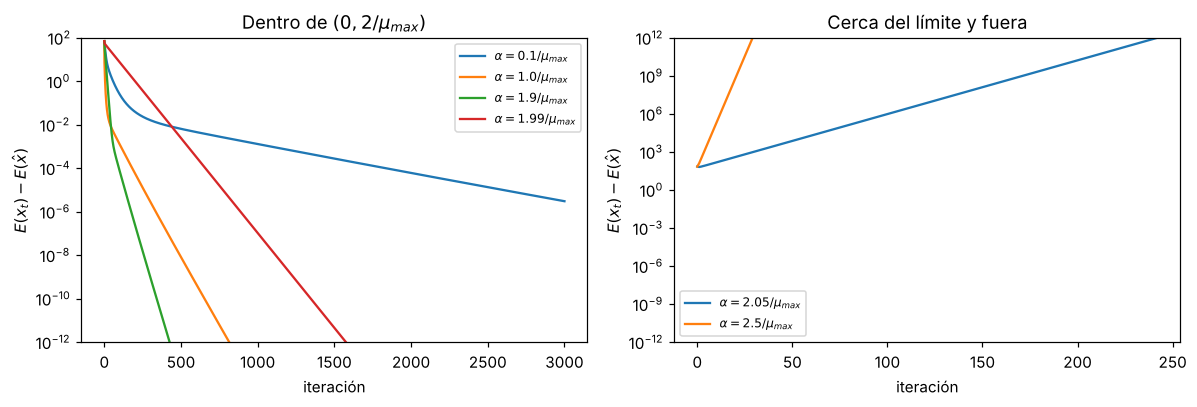

In [ ]:
# alpha = kappa / mu_max. los ultimos dos kappa se pasan de 2 a proposito, para ver que explota
kappas = [0.1, 1.0, 1.9, 1.99, 2.05, 2.5]
Eopt = E(x_ls)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
print(f"{'kappa':>6} {'alpha':>9} {'iter':>6} {'E final - E*':>14}  estado")
for kp in kappas:
    a = kp / mu_max
    xk, ck, gk, itk = gradiente_descendiente(grad_E, E, np.zeros(64), a, max_iter=3000, tol=1e-10, corte_cost=1e12)
    if not np.isfinite(ck[-1]) or ck[-1] > 1e12:
        estado = "DIVERGE"
    elif gk[-1] <= 1e-10 * gk[0]:
        estado = "converge"
    else:
        estado = "no llegó a la tolerancia en 3000 it."
    print(f"{kp:>6} {a:>9.5f} {itk:>6d} {ck[-1]-Eopt:>14.3e}  {estado}")
    (ax[0] if kp < 2 else ax[1]).semilogy(np.maximum(ck - Eopt, 1e-20), label=rf"$\alpha={kp}/\mu_{{max}}$")
ax[0].set_title(r"Dentro de $(0, 2/\mu_{max})$"); ax[1].set_title(r"Cerca del límite y fuera")
for a_ in ax:
    a_.set_xlabel("iteración"); a_.set_ylabel(r"$E(x_t)-E(\hat x)$"); a_.legend(fontsize=8)
ax[0].set_ylim(1e-12, 1e2); ax[1].set_ylim(1e-12, 1e12)
plt.tight_layout(); plt.savefig("figuras/ejercicio_8_c.png", dpi=150); plt.show()

Con 0 < kappa < 2 el método converge siempre. La velocidad la fija el mayor valor de |1 - alpha * mu_i|. Con alpha = 1/mu_max ese factor es 1 - mu_min/mu_max, cerca de 0,986 porque H está mal condicionada, y hacen falta unas mil iteraciones. Con alpha muy chico (0,1/mu_max) converge, pero unas diez veces más despacio: no llega a la tolerancia en 3000 iteraciones.

Cerca del límite superior (1,9/mu_max y 1,99/mu_max) la componente del error en la dirección de mu_max se multiplica por -0,9 o -0,99. Cambia de signo en cada paso, pero su módulo decrece, así que el costo sigue bajando de forma monótona. Con 1,9/mu_max el método es incluso más rápido que con 1/mu_max (611 contra 1169 iteraciones), porque las direcciones de curvatura chica avanzan casi el doble por paso. Con 1,99/mu_max el factor 0,99 casi no contrae esa componente y se necesitan más de 2000 iteraciones.

Fuera del intervalo (2,05/mu_max y 2,5/mu_max) el factor en la dirección de mu_max tiene módulo > 1 y el error crece geométricamente: el costo explota aunque en las demás direcciones el método sí baje.

Entonces la tasa de aprendizaje queda acotada por el mayor autovalor de H (la mayor curvatura), mientras que la cantidad de iteraciones depende del cociente mu_max/mu_min.

## Inciso d) 

In [ ]:
def newton(grad, hess, x0, max_iter=10, tol=1e-12):
    x = x0.copy()
    hist_g = [np.linalg.norm(grad(x))]
    for t in range(max_iter):
        p = np.linalg.solve(hess, grad(x))
        x = x - p
        hist_g.append(np.linalg.norm(grad(x)))
        if hist_g[-1] <= tol * max(hist_g[0], 1.0):
            break
    return x, hist_g

# un solo paso y ya esta, la explicacion va abajo
x_newton, hist_g = newton(grad_E, H, np.zeros(64), max_iter=3)
print("||grad E|| en x0 y despues de cada paso:", ["%.2e" % g for g in hist_g])

||grad E|| en x0 y despues de cada paso: ['6.67e+01', '1.67e-14']


Como E es cuadrática, su desarrollo de Taylor de segundo orden es exacto, con H constante. Newton minimiza justamente ese modelo cuadrático en cada paso, y su minimizador es x0 - H^(-1) * gradiente(x0) (existe y es único porque H es definida positiva). Como el modelo coincide con E, ese punto es el mínimo de E: el gradiente en x1 vale gradiente(x0) - H * H^(-1) gradiente(x0) = 0. Equivalentemente, con x0 = 0, x1 = H^(-1) A7^T b_sigma, que son las ecuaciones normales. Las iteraciones siguientes ya no cambian nada porque el paso es cero.

## Inciso e) 

método           iteraciones       costo E     ||r||  err. rel. vs fantoma   ||x - x_lstsq||
lstsq           directo (SVD)      0.142363    0.5336                0.1261          0.00e+00
Gradiente desc.         1169      0.142363    0.5336                0.1261          1.29e-08
Newton                     1      0.142363    0.5336                0.1261          6.97e-15


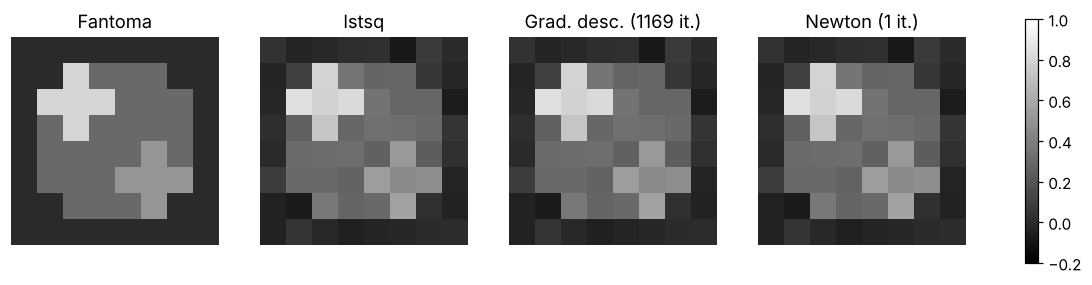

In [ ]:
sol = {"lstsq": x_ls, "Gradiente desc.": x_gd, "Newton": x_newton}
nx = np.linalg.norm(x_fantoma)
print(f"{'método':<16}{'iteraciones':>12}{'costo E':>14}{'||r||':>10}{'err. rel. vs fantoma':>22}{'||x - x_lstsq||':>18}")
iters = {"lstsq": "directo (SVD)", "Gradiente desc.": it_gd, "Newton": 1}
for k, x in sol.items():
    print(f"{k:<16}{str(iters[k]):>12}{E(x):>14.6f}{np.linalg.norm(A7@x-b_sigma):>10.4f}{np.linalg.norm(x-x_fantoma)/nx:>22.4f}{np.linalg.norm(x-x_ls):>18.2e}")

VMIN, VMAX = -0.2, 1.0
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, (t, im) in zip(axes, [("Fantoma", X_fantoma), ("lstsq", x_ls.reshape(8, 8)),
                              (f"Grad. desc. ({it_gd} it.)", x_gd.reshape(8, 8)), ("Newton (1 it.)", x_newton.reshape(8, 8))]):
    h = ax.imshow(im, cmap="gray", vmin=VMIN, vmax=VMAX); ax.set_title(t); ax.axis("off")
fig.colorbar(h, ax=axes, shrink=0.8)
plt.savefig("figuras/ejercicio_8_e.png", dpi=150, bbox_inches="tight"); plt.show()

Los tres métodos llegan a la misma reconstrucción: las diferencias relativas son del orden de 1e-8 para gradiente descendiente (depende de la tolerancia de parada) y de 1e-15 para Newton (error de redondeo). Esto pasa porque el problema tiene un único mínimo. Los tres tienen el mismo costo, el mismo residuo y el mismo error respecto del fantoma; el error no es cero porque el ruido se filtra, y el mínimo de E no es el fantoma.

lstsq es un método directo y no tiene parámetros que elegir.

Gradiente descendiente requiere elegir 0 < alpha < 2/mu_max, un criterio de parada y la cantidad de iteraciones (cientos, por el mal condicionamiento de H). Solo usa productos matriz-vector, lo que escala bien a problemas grandes y ralos, como el del Ejercicio 10.

Newton no necesita tasa de aprendizaje y termina en una iteración, pero cada iteración exige resolver un sistema con H, que es de n^2 x n^2. Para imágenes de 128 x 128, H sería de 16384 x 16384 y esa resolución directa deja de ser razonable.